In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re

## NBA Injuries dataset

In [2]:
nba_injuries = pd.read_csv("injuries_2010-2020.csv")

print(nba_injuries.describe())
nba_injuries.head()

              Date   Team     Acquired Relinquished              Notes
count        27105  27103         9542        17560              27105
unique        2103     32         1111         1156               3114
top     2014-04-16  Spurs  Dwyane Wade   Kevin Love  activated from IL
freq            76   1163           54          101               7342


,Date,Team,Acquired,Relinquished,Notes
0,2010-10-03,Bulls,NaN,Carlos Boozer,fractured bone in right pinky finger (out inde...
1,2010-10-06,Pistons,NaN,Jonas Jerebko,torn right Achilles tendon (out indefinitely)
2,2010-10-06,Pistons,NaN,Terrico White,broken fifth metatarsal in right foot (out ind...
3,2010-10-08,Blazers,NaN,Jeff Ayres,torn ACL in right knee (out indefinitely)
4,2010-10-08,Nets,NaN,Troy Murphy,strained lower back (out indefinitely)


In [3]:
#DATA CLEANING
nba_injuries.columns = [c.strip().lower() for c in nba_injuries.columns]
nba_injuries["date"] = pd.to_datetime(nba_injuries["date"])
 
#Pro Sports Transactions entries are often prefixed with a bullet char
def clean_name(x):
    if pd.isna(x):
        return np.nan
    return re.sub(r"^[•\s]+", "", str(x)).strip()
 
nba_injuries["acquired"] = nba_injuries["acquired"].apply(clean_name)
nba_injuries["relinquished"] = nba_injuries["relinquished"].apply(clean_name)

#a filled "relinquished" = player placed on the injury list (injury START)
#a filled "acquired" = player activated / returned (injury END)
nba_injuries["event_type"] = np.where(
    nba_injuries["relinquished"].notna(),
    "placed_on_IL",
    np.where(nba_injuries["acquired"].notna(), "activated", "other"))

nba_injuries["player"] = nba_injuries["relinquished"].fillna(nba_injuries["acquired"])
 
#nba seasons run Oct-June - bucket by season-start year for consistency with nba_games
nba_injuries["season"] = nba_injuries["date"].apply(lambda d: d.year if d.month >= 10 else d.year - 1)
 
print("Event type breakdown:\n", nba_injuries["event_type"].value_counts())

Event type breakdown:
 event_type
placed_on_IL    17560
activated        9541
other               4
Name: count, dtype: int64


In [4]:
#what does being on IL mean?
il_notes = nba_injuries.loc[nba_injuries["event_type"] == "placed_on_IL", "notes"]
print(il_notes.str.lower().value_counts().head(30))

# flag likely non-injury entries for a manual look
non_injury_flags = il_notes[il_notes.str.contains("rest|personal|suspend|coach|g league|g-league|conditioning", case = False, na = False)]

print(f"\n{len(non_injury_flags)} of {len(il_notes)} placed_on_IL rows may be non-injury")
print(non_injury_flags.value_counts().head(20))

notes
placed on il                              3389
sprained left ankle (dnp)                  362
rest (dtd)                                 286
placed on il with illness                  274
placed on il with sprained left ankle      230
illness (dtd)                              228
placed on il with sprained right ankle     206
sprained left ankle (dtd)                  188
sprained right ankle (dnp)                 175
placed on il for rest                      175
sprained right ankle (dtd)                 166
sore left knee (dnp)                       144
placed on il with sore left knee           128
placed on il with sore right knee          119
rest (dnp)                                 119
sore right knee (dnp)                      109
sore left knee (dtd)                       109
illness (dnp)                              100
sore right knee (dtd)                       97
concussion (dnp)                            96
placed on il with concussion                95
back sp

In [5]:
#discovered and removing coaches
coach_mask = nba_injuries["notes"].str.contains("coach", case = False, na = False)
print(f"Excluding {coach_mask.sum()} coach/staff rows (not player injuries)")

nba_injuries.loc[coach_mask, "event_type"] = "non_player_event"
print(f"\nAfter:\n", nba_injuries["event_type"].value_counts())

Excluding 14 coach/staff rows (not player injuries)

After:
 event_type
placed_on_IL        17551
activated            9536
non_player_event       14
other                   4
Name: count, dtype: int64


In [6]:
#discovered 76ers team name mistakenly recorded as the player
print(nba_injuries[nba_injuries["player"] == "76ers"])

            date   team acquired relinquished         notes    event_type  \
23271 2018-12-27  76ers      NaN        76ers  placed on IL  placed_on_IL   

      player  season  
23271  76ers    2018  


In [7]:
team_names = set(nba_injuries["team"].unique())
malformed = nba_injuries[nba_injuries["player"].isin(team_names)]

print(malformed[["date", "team", "player", "notes"]])

            date     team player                                    notes
23161 2018-12-19    Bucks    NaN                             placed on IL
23271 2018-12-27    76ers  76ers                             placed on IL
24309 2019-03-16     Nets    NaN                        activated from IL
25779 2019-12-31  Thunder    NaN                        activated from IL
26756 2020-07-09  Wizards    NaN  COVID-19 coronavirus (out indefinitely)


In [8]:
nba_injuries.loc[nba_injuries["player"] == "76ers", "event_type"] = "data_artifact"
print(nba_injuries["event_type"].value_counts())

event_type
placed_on_IL        17550
activated            9536
non_player_event       14
other                   4
data_artifact           1
Name: count, dtype: int64


## NBA Games dataset

In [9]:
nba_games = pd.read_csv("games.csv")

print(nba_games.describe())
nba_games.head()

            GAME_ID  HOME_TEAM_ID  VISITOR_TEAM_ID        SEASON  \
count  2.665100e+04  2.665100e+04     2.665100e+04  26651.000000   
mean   2.175487e+07  1.610613e+09     1.610613e+09   2012.113879   
std    5.570189e+06  8.638670e+00     8.659299e+00      5.587031   
min    1.030000e+07  1.610613e+09     1.610613e+09   2003.000000   
25%    2.070001e+07  1.610613e+09     1.610613e+09   2007.000000   
50%    2.120076e+07  1.610613e+09     1.610613e+09   2012.000000   
75%    2.180005e+07  1.610613e+09     1.610613e+09   2017.000000   
max    5.210021e+07  1.610613e+09     1.610613e+09   2022.000000   

       TEAM_ID_home      PTS_home   FG_PCT_home   FT_PCT_home  FG3_PCT_home  \
count  2.665100e+04  26552.000000  26552.000000  26552.000000  26552.000000   
mean   1.610613e+09    103.455898      0.460735      0.760377      0.356023   
std    8.638670e+00     13.283370      0.056676      0.100677      0.111164   
min    1.610613e+09     36.000000      0.250000      0.143000      0.00

,GAME_DATE_EST,GAME_ID,GAME_STATUS_TEXT,HOME_TEAM_ID,VISITOR_TEAM_ID,SEASON,TEAM_ID_home,PTS_home,FG_PCT_home,FT_PCT_home,...,AST_home,REB_home,TEAM_ID_away,PTS_away,FG_PCT_away,FT_PCT_away,FG3_PCT_away,AST_away,REB_away,HOME_TEAM_WINS
0,2022-12-22,22200477,Final,1610612740,1610612759,2022,1610612740,126.0,0.484,0.926,...,25.0,46.0,1610612759,117.0,0.478,0.815,0.321,23.0,44.0,1
1,2022-12-22,22200478,Final,1610612762,1610612764,2022,1610612762,120.0,0.488,0.952,...,16.0,40.0,1610612764,112.0,0.561,0.765,0.333,20.0,37.0,1
2,2022-12-21,22200466,Final,1610612739,1610612749,2022,1610612739,114.0,0.482,0.786,...,22.0,37.0,1610612749,106.0,0.470,0.682,0.433,20.0,46.0,1
3,2022-12-21,22200467,Final,1610612755,1610612765,2022,1610612755,113.0,0.441,0.909,...,27.0,49.0,1610612765,93.0,0.392,0.735,0.261,15.0,46.0,1
4,2022-12-21,22200468,Final,1610612737,1610612741,2022,1610612737,108.0,0.429,1.000,...,22.0,47.0,1610612741,110.0,0.500,0.773,0.292,20.0,47.0,0


In [10]:
##DATA CLEANING
nba_games.columns = [c.strip().lower() for c in nba_games.columns]
nba_games["game_date_est"] = pd.to_datetime(nba_games["game_date_est"])

## NBA Games Details dataset

In [11]:
nba_details = pd.read_csv("games_details.csv", low_memory = False)

print(nba_details.describe())
nba_details.head()

            GAME_ID       TEAM_ID     PLAYER_ID            FGM            FGA  \
count  6.686280e+05  6.686280e+05  6.686280e+05  558938.000000  558938.000000   
mean   2.171771e+07  1.610613e+09  4.013434e+05       3.588446       7.896652   
std    5.656289e+06  8.652260e+00  7.225618e+06       3.030466       5.677002   
min    1.030000e+07  1.610613e+09  1.500000e+01       0.000000       0.000000   
25%    2.070003e+07  1.610613e+09  2.466000e+03       1.000000       3.000000   
50%    2.120096e+07  1.610613e+09  2.011810e+05       3.000000       7.000000   
75%    2.180014e+07  1.610613e+09  2.034710e+05       5.000000      11.000000   
max    5.210021e+07  1.610613e+09  1.962938e+09      28.000000      50.000000   

              FG_PCT           FG3M           FG3A        FG3_PCT  \
count  558938.000000  558938.000000  558938.000000  558938.000000   
mean        0.416842       0.778117       2.186019       0.201032   
std         0.251913       1.227615       2.569913       0.2896

,GAME_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_CITY,PLAYER_ID,PLAYER_NAME,NICKNAME,START_POSITION,COMMENT,MIN,...,OREB,DREB,REB,AST,STL,BLK,TO,PF,PTS,PLUS_MINUS
0,22200477,1610612759,SAS,San Antonio,1629641,Romeo Langford,Romeo,F,NaN,18:06,...,1.0,1.0,2.0,0.0,1.0,0.0,2.0,5.0,2.0,-2.0
1,22200477,1610612759,SAS,San Antonio,1631110,Jeremy Sochan,Jeremy,F,NaN,31:01,...,6.0,3.0,9.0,6.0,1.0,0.0,2.0,1.0,23.0,-14.0
2,22200477,1610612759,SAS,San Antonio,1627751,Jakob Poeltl,Jakob,C,NaN,21:42,...,1.0,3.0,4.0,1.0,1.0,0.0,2.0,4.0,13.0,-4.0
3,22200477,1610612759,SAS,San Antonio,1630170,Devin Vassell,Devin,G,NaN,30:20,...,0.0,9.0,9.0,5.0,3.0,0.0,2.0,1.0,10.0,-18.0
4,22200477,1610612759,SAS,San Antonio,1630200,Tre Jones,Tre,G,NaN,27:44,...,0.0,2.0,2.0,3.0,0.0,0.0,2.0,2.0,19.0,0.0


In [12]:
##DATA CLEANING
nba_details.columns = [c.strip().lower() for c in nba_details.columns]
 
#bring game_date/season onto the player-level rows for joining
nba_details = nba_details.merge(nba_games[["game_id", "game_date_est", "season"]], on = "game_id", how = "left")
nba_details["player_name"] = nba_details["player_name"].str.strip()
 
#normalize MIN column
def minutes_to_float(m):
    if pd.isna(m):
        return np.nan
    m = str(m)
    if ":" in m:
        mins, secs = m.split(":")
        return float(mins) + float(secs) / 60
    try:
        return float(m)
    except ValueError:
        return np.nan
 
nba_details["minutes"] = nba_details["min"].apply(minutes_to_float)

## Join Datasets

In [13]:
#exact match notes that represent non-injury absences or data artifacts 

non_injury_notes = [
    "rest (dtd)",
    "placed on il for rest",
    "rest (dnp)",
    "rest (out for season)",
    "placed on il for personal reasons",
    "placed on il for rest (out for season)",
    "placed on il with conditioning",
    "conditioning (dnp)",
    "head coach illness (dtd)"]

is_non_injury = nba_injuries["notes"].str.lower().isin(non_injury_notes)
print(f"Excluding {is_non_injury.sum()} non-injury / data-artifact rows")

#redefine event_type so these no longer count as placed_on_IL
nba_injuries.loc[(nba_injuries["event_type"] == "placed_on_IL") & is_non_injury, "event_type"] = "non_injury_absence"

Excluding 620 non-injury / data-artifact rows


In [14]:
#player-name matching between the two sources is exact-string based here
played_only = nba_details[nba_details["minutes"] > 0]

games_played = (
    played_only.groupby(["player_name", "season"])["game_id"]
    .nunique()
    .reset_index(name = "games_played"))

season_workload = (
    nba_details.groupby(["player_name", "season"])
    .agg(
        avg_minutes = ("minutes", "mean"),
        total_minutes = ("minutes", "sum"),
        total_points = ("pts", "sum")).reset_index())

season_workload = season_workload.merge(games_played, on = ["player_name", "season"], how = "left")
season_workload["games_played"] = season_workload["games_played"].fillna(0)

injury_counts = (
    nba_injuries[nba_injuries["event_type"] == "placed_on_IL"]
    .groupby(["player", "season"])
    .size()
    .reset_index(name = "injury_count"))

In [15]:
#filter both sources to the seasons where injury data actually exists (2010–2019)
valid_seasons = range(2010, 2020)

season_workload = season_workload[season_workload["season"].isin(valid_seasons)]
injury_counts = injury_counts[injury_counts["season"].isin(valid_seasons)]

#address Phantom seasons that showed players played, but they actually didnt
season_workload = season_workload[season_workload["games_played"] > 0]

player_season = season_workload.merge(
    injury_counts,
    left_on = ["player_name", "season"],
    right_on = ["player", "season"],
    how = "left").drop(columns = ["player"])

player_season["injury_count"] = player_season["injury_count"].fillna(0)
player_season["was_injured"] = (player_season["injury_count"] > 0).astype(int)

print("player_season sample:\n", player_season.head())

match_rate = player_season["was_injured"].mean()
print(f"\n{match_rate:.1%} of player-seasons have at least one recorded IL placement")
print(f"placed_on_IL rows before filtering non-injury notes: 17,560")
print(f"placed_on_IL rows after filtering: {(nba_injuries['event_type'] == 'placed_on_IL').sum()}")

player_season sample:
   player_name  season  avg_minutes  total_minutes  total_points  games_played  \
0  AJ Hammons    2016     8.476437     245.816667          82.0          29.0   
1    AJ Price    2010    15.873118     984.133333         430.0          62.0   
2    AJ Price    2011    11.787415     577.583333         178.0          49.0   
3    AJ Price    2012    22.184615    1442.000000         518.0          65.0   
4    AJ Price    2013     4.542708     145.366667          69.0          32.0   

   injury_count  was_injured  
0           0.0            0  
1           0.0            0  
2           0.0            0  
3           0.0            0  
4           0.0            0  

64.4% of player-seasons have at least one recorded IL placement
placed_on_IL rows before filtering non-injury notes: 17,560
placed_on_IL rows after filtering: 16935


## EDA

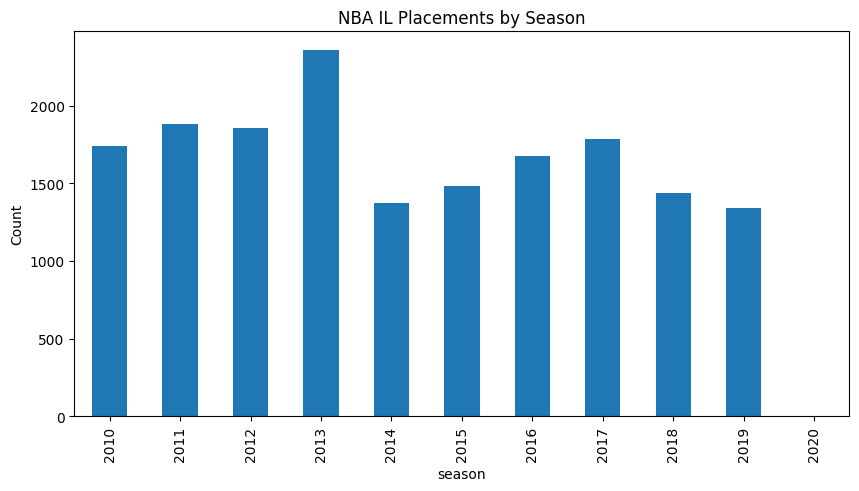

In [16]:
#Injury Events by Season
injuries_per_season = (nba_injuries[nba_injuries["event_type"] == "placed_on_IL"].groupby("season").size())
injuries_per_season.plot(kind = "bar", figsize = (10, 5), title = "NBA IL Placements by Season")

plt.ylabel("Count")
plt.savefig("injury_events_season.png")
plt.show()

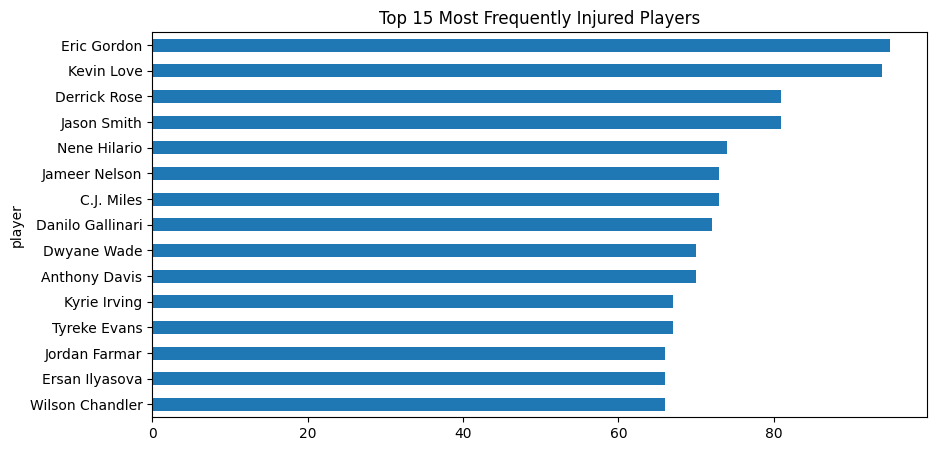

In [17]:
#Top 15 Most Frequently Injured Players
top_injured = (nba_injuries[nba_injuries["event_type"] == "placed_on_IL"]["player"].value_counts().head(15))
top_injured.plot(kind = "barh", figsize = (10, 5), title = "Top 15 Most Frequently Injured Players")

plt.gca().invert_yaxis()
plt.savefig("top_15_injured_players.png")
plt.show()

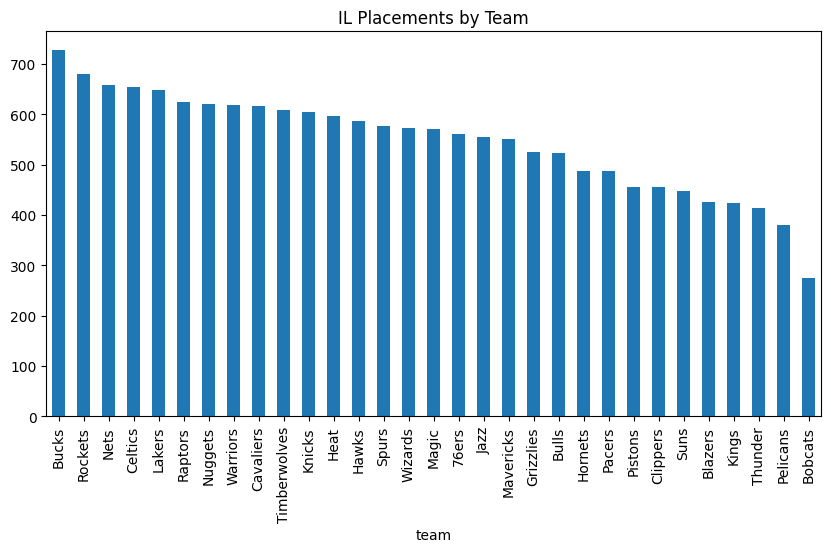

In [18]:
#Injury Events by Team
injuries_by_team = (nba_injuries[nba_injuries["event_type"] == "placed_on_IL"].groupby("team").size().sort_values(ascending = False))
injuries_by_team.plot(kind = "bar", figsize = (10, 5), title = "IL Placements by Team")

plt.savefig("injury_events_team.png")
plt.show()

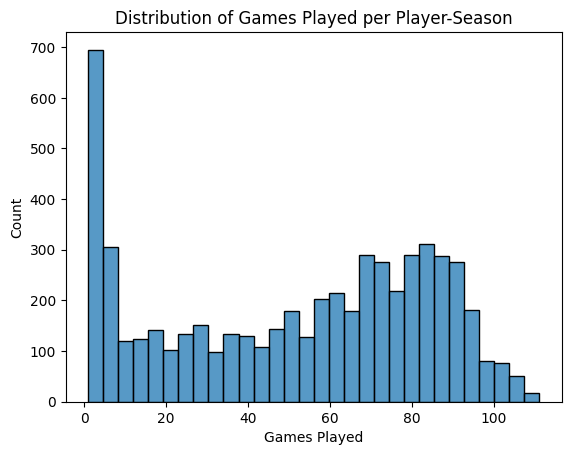

In [19]:
#Distribution of Games Played per player-season (workload spread)
sns.histplot(season_workload["games_played"], bins = 30)

plt.title("Distribution of Games Played per Player-Season")
plt.xlabel("Games Played")
plt.savefig("workload_spread.png")
plt.show()

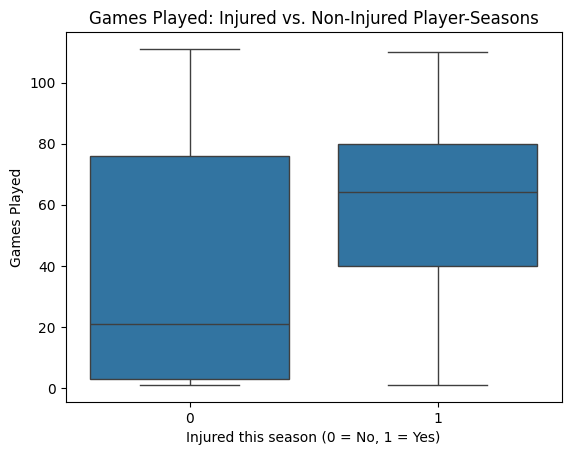

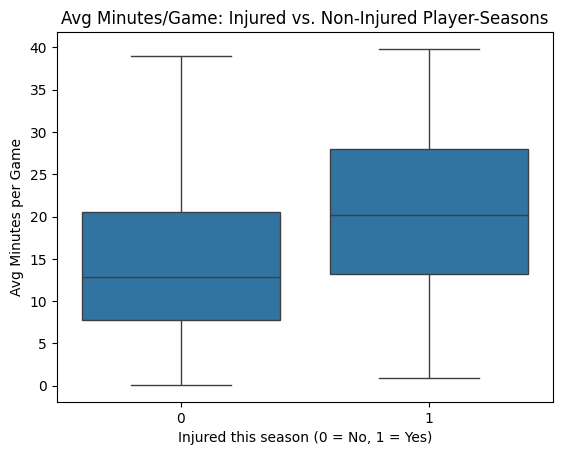

In [20]:
#Workload Comparison: Injured vs Non-Injured player-seasons
sns.boxplot(data = player_season, x = "was_injured", y = "games_played")
plt.title("Games Played: Injured vs. Non-Injured Player-Seasons")
plt.xlabel("Injured this season (0 = No, 1 = Yes)")
plt.ylabel("Games Played")
plt.savefig("games_played_injury.png")
plt.show()
 
sns.boxplot(data = player_season, x = "was_injured", y = "avg_minutes")
plt.title("Avg Minutes/Game: Injured vs. Non-Injured Player-Seasons")
plt.xlabel("Injured this season (0 = No, 1 = Yes)")
plt.ylabel("Avg Minutes per Game")
plt.savefig("avg_mins_game.png")
plt.show()

In [21]:
#summary stats
summary = player_season.groupby("was_injured")[["games_played", "avg_minutes", "total_minutes"]].describe()

print("Summary stats by injury status:\n", summary)

Summary stats by injury status:
             games_played                                                      \
                   count       mean        std  min   25%   50%   75%    max   
was_injured                                                                    
0                 2006.0  37.988036  36.951284  1.0   3.0  21.0  76.0  111.0   
1                 3636.0  58.954345  26.513324  1.0  40.0  64.0  80.0  110.0   

            avg_minutes             ...                       total_minutes  \
                  count       mean  ...        75%        max         count   
was_injured                         ...                                       
0                2006.0  14.900271  ...  20.493280  39.047518        2006.0   
1                3636.0  20.532903  ...  27.946247  39.825758        3636.0   

                                                                       \
                    mean          std       min         25%       50%   
was_injured             

## Feature Engineering

In [22]:
#1. PLAYER GAME LOG — one row per player per game actually played

#how many days ahead counts as "at-risk" for the label
INJURY_WINDOW_DAYS = 7  

player_games = (
    nba_details[nba_details["minutes"] > 0]
    [["player_name", "team_abbreviation", "season", "game_id", "game_date_est", "minutes", "pts"]]
    .dropna(subset = ["game_date_est"])
    .sort_values(["player_name", "game_date_est"])
    .reset_index(drop = True))
 
print("player_games shape:", player_games.shape)

player_games shape: (559486, 7)


In [23]:
#2. TEAM SCHEDULE — back-to-backs are a TEAM property, not a player one
team_games = (
    nba_details[["team_abbreviation", "game_id", "game_date_est"]]
    .drop_duplicates()
    .sort_values(["team_abbreviation", "game_date_est"]))
 
team_games["prev_team_game_date"] = team_games.groupby("team_abbreviation")["game_date_est"].shift(1)
team_games["team_days_rest"] = (team_games["game_date_est"] - team_games["prev_team_game_date"]).dt.days
team_games["is_back_to_back"] = (team_games["team_days_rest"] == 1).astype(int)
 
player_games = player_games.merge(
    team_games[["team_abbreviation", "game_id", "team_days_rest", "is_back_to_back"]],
    on = ["team_abbreviation", "game_id"],
    how = "left")

In [24]:
#3. PLAYER-LEVEL ROLLING WORKLOAD FEATURES
player_games = player_games.sort_values(["player_name", "game_date_est"])
player_games["prev_game_date"] = player_games.groupby("player_name")["game_date_est"].shift(1)
player_games["player_days_rest"] = (player_games["game_date_est"] - player_games["prev_game_date"]).dt.days
player_games["roll5_avg_minutes"] = (player_games.groupby("player_name")["minutes"]
                                     .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()))
player_games["roll10_avg_minutes"] = (player_games.groupby("player_name")["minutes"]
                                      .transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean()))
player_games["roll5_sum_minutes"] = (player_games.groupby("player_name")["minutes"]
                                     .transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum()))
 
#cumulative season workload up to (not including) this game
player_games["season_cum_minutes"] = (player_games.groupby(["player_name", "season"])["minutes"].transform(lambda s: s.shift(1).cumsum()))
 
#how many of the trailing 5 games were back-to-backs
player_games["b2b_last5"] = (player_games.groupby("player_name")["is_back_to_back"]
                             .transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum()))

In [25]:
#4. FORWARD-LOOKING INJURY LABEL
def normalize_name(name):
    if pd.isna(name):
        return name
    name = str(name).strip()
    name = re.sub(r"\.", "", name)  #C.J. > CJ
    name = re.sub(r"\s+(Jr|Sr|II|III|IV)\.?$", "", name, flags = re.IGNORECASE)  #strip suffix
    name = re.sub(r"\s+", " ", name)  #collapse leftover double spaces
    return name.strip()

player_games["player_name_norm"] = player_games["player_name"].apply(normalize_name)

injury_events = (
    nba_injuries[nba_injuries["event_type"] == "placed_on_IL"]
    [["player", "date"]]
    .rename(columns={"player": "player_name", "date": "injury_date"})
    .dropna()
    .sort_values("injury_date"))

injury_events["player_name_norm"] = injury_events["player_name"].apply(normalize_name)

In [26]:
#sanity check before rejoining
injury_players_norm = set(injury_events["player_name_norm"].unique())
game_players_norm = set(player_games["player_name_norm"].unique())
matched_norm = injury_players_norm & game_players_norm

print(f"{len(matched_norm)} of {len(injury_players_norm)} injured players found ({len(matched_norm)/len(injury_players_norm):.1%})")
print("\nStill unmatched:", list(injury_players_norm - game_players_norm)[:15])

1117 of 1151 injured players found (97.0%)

Still unmatched: ['DJ Augustine', 'Moe Harkless', 'Ron Artest', 'Domas Sabonis', 'Juan Hernangomez', 'Jeff Pendergraph', 'Qi Zhou', 'Wes Matthews', 'Vince Hunter', 'Robert Vaden', 'Jianlian Yi', 'DeAndre Bembry', 'Didier Mbenga', 'Nene Hilario', "Maurice N'dour"]


In [27]:
#REBUILD THE merge_asof JOIN — using player_name_norm as the match key

#drop columns from the previous (unnormalized) join before rebuilding it
player_games = player_games.drop(
    columns = ["injury_date", "days_to_next_injury", "injured_next_7d"], errors = "ignore")   

player_games = player_games.sort_values("game_date_est")  #merge_asof requires global sort on "on"
injury_events = injury_events.sort_values("injury_date")

player_games = pd.merge_asof(
    player_games,
    injury_events[["player_name_norm", "injury_date"]],
    left_on = "game_date_est",
    right_on = "injury_date",
    by = "player_name_norm",   
    direction = "forward")

player_games["days_to_next_injury"] = (player_games["injury_date"] - player_games["game_date_est"]).dt.days

player_games["injured_next_7d"] = (
    (player_games["days_to_next_injury"] >= 0) & (player_games["days_to_next_injury"] <= INJURY_WINDOW_DAYS)).astype(int)

print(f"Updated positive rate: {player_games['injured_next_7d'].mean():.1%}")

Updated positive rate: 4.2%


In [28]:
#INSPECT
 
feature_cols = [
    "player_name", "season", "game_date_est", "player_days_rest", "roll5_avg_minutes", "roll10_avg_minutes",
    "roll5_sum_minutes", "season_cum_minutes", "is_back_to_back", "team_days_rest", "b2b_last5", "injured_next_7d"]
 
print(player_games[feature_cols].sample(10, random_state = 42))
print(f"\nOverall positive rate: {player_games['injured_next_7d'].mean():.1%} of games precede an injury within {INJURY_WINDOW_DAYS} days")
 
na_counts = player_games[feature_cols].isna().sum()
print(f"\nMissing values per feature (expected for players' first games / first of season):")
print(na_counts[na_counts > 0])

             player_name  season game_date_est  player_days_rest  \
283829  Maurice Harkless    2013    2013-10-16               2.0   
212011       Ben Wallace    2010    2010-12-29               2.0   
372485      Festus Ezeli    2015    2016-04-27               3.0   
552529     Terence Davis    2022    2022-11-07               2.0   
328896      Brandon Rush    2014    2015-01-21               2.0   
35586      Rashard Lewis    2004    2004-12-30               2.0   
543121    Grant Williams    2021    2022-03-27               4.0   
184515      Luke Ridnour    2009    2010-01-13               2.0   
454095      Dion Waiters    2018    2019-02-21               8.0   
101021      Marcus Banks    2006    2007-02-09               3.0   

        roll5_avg_minutes  roll10_avg_minutes  roll5_sum_minutes  \
283829          32.453333           33.841667         162.266667   
212011          19.620000           24.101667          98.100000   
372485           9.240000            9.268333  

## Modeling

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, classification_report, roc_auc_score)
from sklearn.preprocessing import StandardScaler

In [30]:
#FILTER TO SEASONS WHERE THE INJURY LABEL IS ACTUALLY RELIABLE
model_df = player_games[player_games["season"].isin(valid_seasons)].copy()

print(f"Rows before season filter: {len(player_games):,} | after: {len(model_df):,}")

Rows before season filter: 559,486 | after: 290,563


In [31]:
print(model_df[["roll5_avg_minutes", "roll5_sum_minutes"]].corr())

                   roll5_avg_minutes  roll5_sum_minutes
roll5_avg_minutes           1.000000           0.994225
roll5_sum_minutes           0.994225           1.000000


Dropped 5,642 rows with incomplete rolling features (1.9%)

Final positive rate: 8.3%


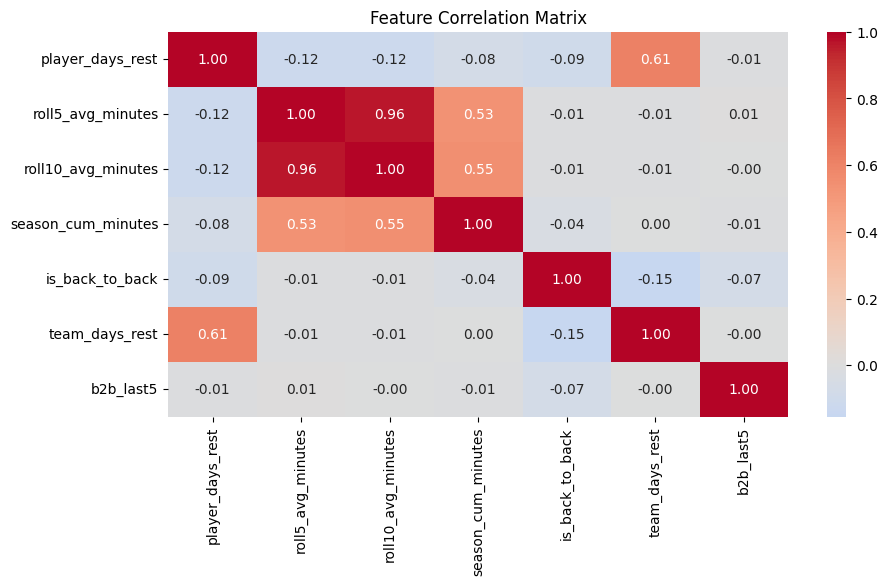

In [32]:
#FINALIZE FEATURE SET AND DROP INCOMPLETE ROWS
feature_cols = [
    "player_days_rest",
    "roll5_avg_minutes",
    "roll10_avg_minutes",
    #"roll5_sum_minutes",
    "season_cum_minutes",
    "is_back_to_back",
    "team_days_rest",
    "b2b_last5"]
target_col = "injured_next_7d"
 
before = len(model_df)
model_df = model_df.dropna(subset = feature_cols)
print(f"Dropped {before - len(model_df):,} rows with incomplete rolling features "
      f"({(before - len(model_df)) / before:.1%})")
 
print(f"\nFinal positive rate: {model_df[target_col].mean():.1%}")
 
# Quick multicollinearity check — several of these features are built from the
# same underlying "minutes" signal, so expect meaningful correlation
plt.figure(figsize = (10, 5))
sns.heatmap(model_df[feature_cols].corr(), annot = True, fmt = ".2f", cmap = "coolwarm", center = 0)
plt.title("Feature Correlation Matrix")
plt.show()

In [33]:
#TIME-BASED TRAIN/TEST SPLIT (by season, not random)
TRAIN_SEASONS = range(2010, 2018)   # 2010-2017
TEST_SEASONS = range(2018, 2020)    # 2018-2019
 
train_df = model_df[model_df["season"].isin(TRAIN_SEASONS)]
test_df = model_df[model_df["season"].isin(TEST_SEASONS)]
 
X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]
 
print(f"Train: {len(X_train):,} rows ({y_train.mean():.1%} positive)")
print(f"\nTest:  {len(X_test):,} rows ({y_test.mean():.1%} positive)")

Train: 229,672 rows (8.1% positive)

Test:  55,249 rows (9.0% positive)


In [34]:
#BASELINE MODEL — Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
 
logreg = LogisticRegression(class_weight = "balanced", max_iter = 1000, random_state = 42)
logreg.fit(X_train_scaled, y_train)
 
logreg_pred = logreg.predict(X_test_scaled)
logreg_proba = logreg.predict_proba(X_test_scaled)[:, 1]
 
print("LOGISTIC REGRESSION (baseline):")
print(classification_report(y_test, logreg_pred, target_names = ["No Injury", "Injury"]))
print(f"ROC-AUC: {roc_auc_score(y_test, logreg_proba):.3f}")
 
# Coefficients show direction/magnitude of each feature's association
coef_table = pd.DataFrame({
    "feature": feature_cols,
    "coefficient": logreg.coef_[0],
}).sort_values("coefficient", key = abs, ascending = False)

print("\nLogistic regression coefficients (standardized features):")
print(coef_table)

LOGISTIC REGRESSION (baseline):
              precision    recall  f1-score   support

   No Injury       0.92      0.63      0.75     50249
      Injury       0.11      0.48      0.18      5000

    accuracy                           0.61     55249
   macro avg       0.52      0.55      0.46     55249
weighted avg       0.85      0.61      0.70     55249

ROC-AUC: 0.569

Logistic regression coefficients (standardized features):
              feature  coefficient
2  roll10_avg_minutes     0.238192
0    player_days_rest     0.182928
5      team_days_rest    -0.100569
1   roll5_avg_minutes    -0.094247
6           b2b_last5     0.058709
3  season_cum_minutes    -0.034887
4     is_back_to_back    -0.018233


In [35]:
#PRIMARY MODEL — Random Forest
rf = RandomForestClassifier(
    n_estimators = 300,
    max_depth = 8,
    class_weight = "balanced",
    random_state = 42,
    n_jobs = -1)

rf.fit(X_train, y_train)
 
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]
 
print("RANDOM FOREST:")
print(classification_report(y_test, rf_pred, target_names=["No Injury", "Injury"]))
print(f"ROC-AUC: {roc_auc_score(y_test, rf_proba):.3f}")

RANDOM FOREST:
              precision    recall  f1-score   support

   No Injury       0.93      0.54      0.68     50249
      Injury       0.11      0.59      0.19      5000

    accuracy                           0.55     55249
   macro avg       0.52      0.57      0.44     55249
weighted avg       0.86      0.55      0.64     55249

ROC-AUC: 0.587


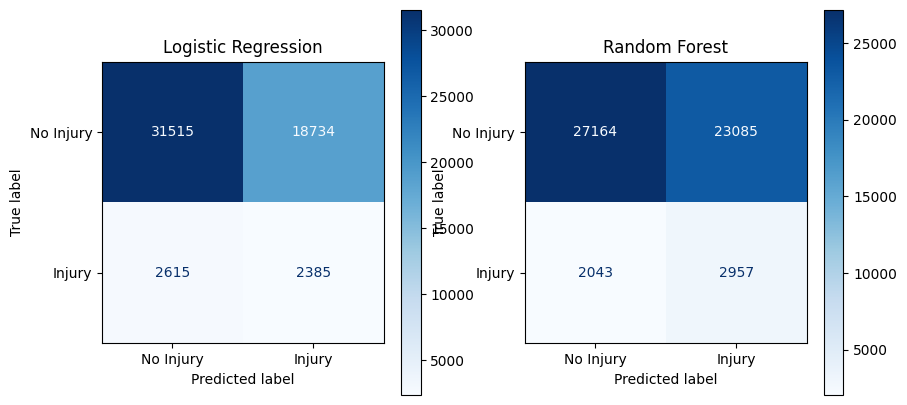

In [36]:
fig, axes = plt.subplots(1, 2, figsize = (10, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, logreg_pred, display_labels = ["No Injury", "Injury"], ax = axes[0], cmap = "Blues")
axes[0].set_title("Logistic Regression")
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, display_labels = ["No Injury", "Injury"], ax=axes[1], cmap="Blues")
axes[1].set_title("Random Forest")
plt.show()

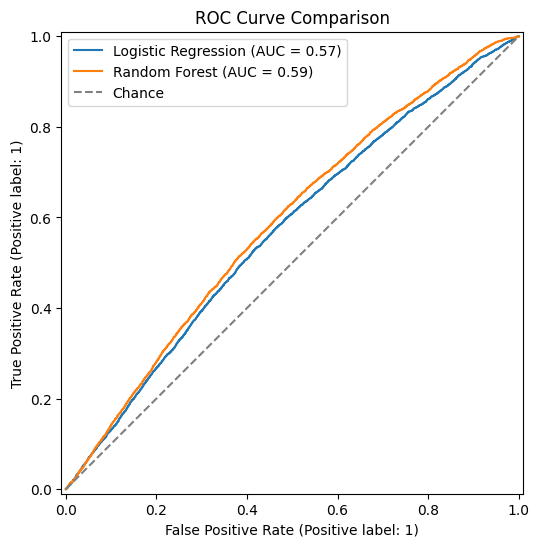

In [37]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, logreg_proba, name = "Logistic Regression", ax = ax)
RocCurveDisplay.from_predictions(y_test, rf_proba, name = "Random Forest", ax = ax)
ax.plot([0, 1], [0, 1], linestyle = "--", color = "gray", label = "Chance")
ax.set_title("ROC Curve Comparison")
ax.legend()
plt.show()

Random Forest feature importances:
              feature  importance
3  season_cum_minutes    0.292294
2  roll10_avg_minutes    0.214725
0    player_days_rest    0.209459
1   roll5_avg_minutes    0.191695
5      team_days_rest    0.044257
6           b2b_last5    0.040047
4     is_back_to_back    0.007522


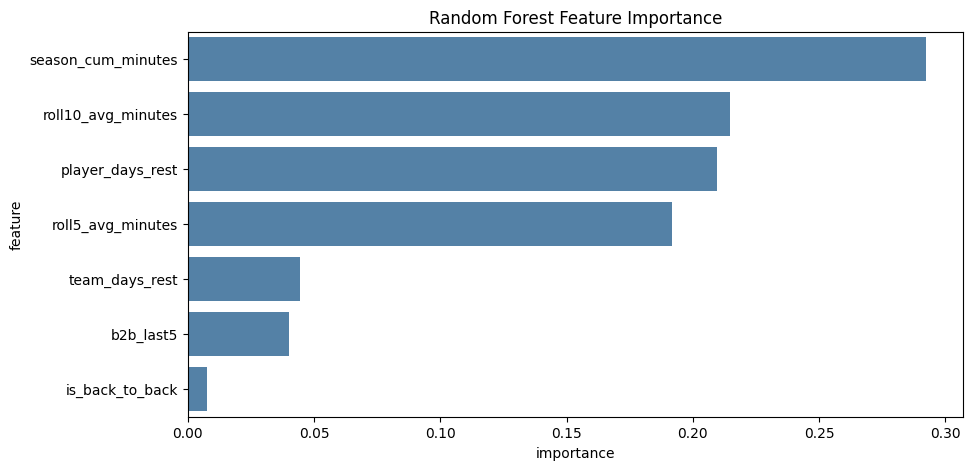

In [38]:
#FEATURE IMPORTANCE (Random Forest) — answers RQ2 from the proposal
importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf.feature_importances_,
}).sort_values("importance", ascending = False)
 
print("Random Forest feature importances:")
print(importance_df)
 
plt.figure(figsize = (10, 5))
sns.barplot(data = importance_df, x = "importance", y = "feature", color = "steelblue")
plt.title("Random Forest Feature Importance")
plt.show()